In [1]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm
import scipy.stats as scis
# from scipy.stats import norm
from cmfa.emu_example import ordered_ilr_func, closure

In [2]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

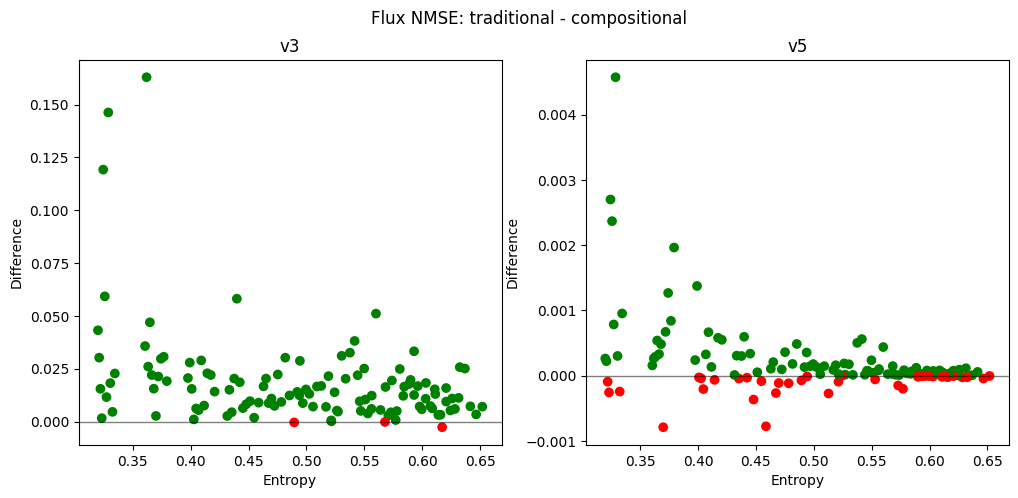

In [3]:
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
true_id_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")
free_fluxes_toy = jnp.load(RESULTS_DIR_TOY / "free_fluxes.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

resid_trad_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["trad"][:, :, [2, 4]])/free_fluxes_toy[:, None, :]
resid_clr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["clr"][:, :, [2, 4]])/free_fluxes_toy[:, None, :]
resid_ilr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["ilr"][:, :, [2, 4]])/free_fluxes_toy[:, None, :]

nmse_trad_toy = (resid_trad_toy ** 2).mean(axis=(0, 1))
nmse_clr_toy = (resid_clr_toy ** 2).mean(axis=(0, 1))
nmse_ilr_toy = (resid_ilr_toy ** 2).mean(axis=(0, 1))

diff_flux_toy = ((resid_trad_toy ** 2).mean(axis=1) - (resid_ilr_toy ** 2).mean(axis=1))

entropies_toy = jnp.load(RESULTS_DIR_TOY / "entropies.npy")

f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

for i in range(2):
    y_values = diff_flux_toy[:, i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_toy, y_values, c=colors)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="Entropy", ylabel="Difference", title=f"v{3+2*i}")
f.suptitle("Flux NMSE: traditional - compositional")
plt.show()


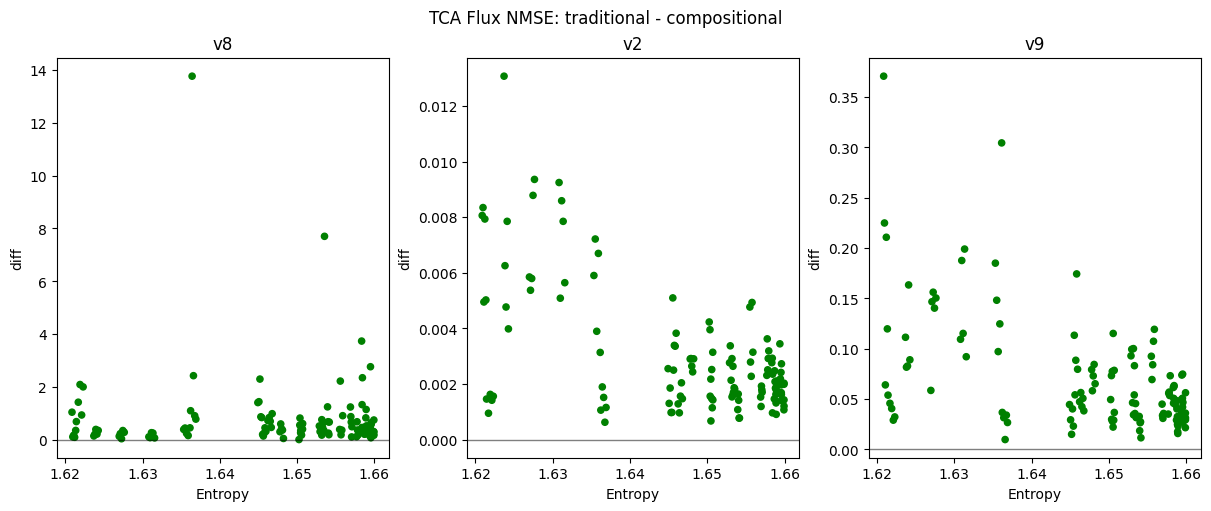

In [4]:
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
true_id_tca = np.load(RESULTS_DIR_TCA / "true_composition.npy", allow_pickle=True).item()
free_fluxes_tca = jnp.load(RESULTS_DIR_TCA / "free_fluxes.npy", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

resid_trad_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["trad"][:, :, :])/free_fluxes_tca[:, None, :]
resid_clr_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["clr"][:, :, :])/free_fluxes_tca[:, None, :]
resid_ilr_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["ilr"][:, :, :])/free_fluxes_tca[:, None, :]

nmse_trad_tca = (resid_trad_tca ** 2).mean(axis=(0, 1))
mmse_clr_tca = (resid_clr_tca ** 2).mean(axis=(0, 1))
nmse_ilr_tca = (resid_ilr_tca ** 2).mean(axis=(0, 1))


with open(RESULTS_DIR_TCA / "entropies.npy", "rb") as f:
    entropies_tca = pickle.load(f)
len(entropies_tca)

entropies_max = [max(idx.values()) for idx in entropies_tca]
diff_flux_tca= ((resid_trad_tca ** 2).mean(axis=1) - (resid_ilr_tca ** 2).mean(axis=1))

free_flux_numbers = jnp.array([8,2,9])

f, axes = plt.subplots(1, 3, figsize=[12, 5], layout= "constrained")
axes = axes.ravel()
point_size=20
for i in range(3):
    y_values = diff_flux_tca[:,i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_max, y_values, c=colors, s=point_size)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5, label="Reference flux")
    axes[i].set(xlabel="Entropy", ylabel="diff", title=f"v{free_flux_numbers[i]}")
f.suptitle("TCA Flux NMSE: traditional - compositional")

plt.show()